In [2]:

#hide
from fastbook import *
from fastai.vision.widgets import *
from fastai.vision.all import *
path = untar_data(URLs.PETS)/'images'

/Users/vikranthkaru/Desktop/abliteration/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
key = os.environ.get('SERP_API_KEY', '20be386e49ebff848f79238899718b23e73b15b1d0cf8d5afb754ea643438648')

In [4]:
search_images_serpapi

<function fastai.vision.utils.search_images_serpapi(term, engine='bing_images', key=None, max_images=150)>

In [5]:

results = search_images_serpapi('grizzly bear', key=key)
ims = results
len(ims)
print(len(ims))

141


In [6]:
print(ims[2])

https://wallup.net/wp-content/uploads/2016/01/30094-bears-nature-animals-Grizzly_bear-Grizzly_Bears.jpg


In [7]:

dest = 'images/grizzly.jpg'
download_url(ims[0], dest)

<div><progress max="103405" value="106496"></progress> 102.99% [106496/103405 00:00&lt;00:00]</div>

Path('images/grizzly.jpg')

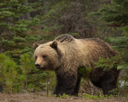

In [18]:

im = Image.open(dest)
im.to_thumb(128,128)

In [10]:
bear_types = ['teddy']
path = Path('bears')


In [25]:
if not path.exists():
    path.mkdir()
    for o in bear_types:
        dest = (path/o)
        dest.mkdir(exist_ok=True)
        results = search_images_serpapi(f'{o} bear', key=key)
        download_images(dest, urls=results)


In [27]:

dest = ('bears/teddy')
results = search_images_serpapi('teddy bear', key=key)
download_images(dest, urls=results)

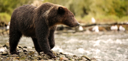

In [33]:
dest = Path('bears/grizzly')
files = list(dest.glob('*'))
im = Image.open(files[2])
im.to_thumb(128,128)

In [8]:
path = Path('bears')
fns = get_image_files(path)
fns

(#306) [Path('bears/grizzly/649913e9-ed7a-48e2-a0bd-91c145b78dfa.jpg'), Path('bears/grizzly/02222eed-9956-4933-9252-b3e7d95e960f.jpg'), Path('bears/grizzly/f0656142-1392-49a7-9cea-2f92ff130b66.jpeg'), Path('bears/grizzly/446829e4-8f80-4765-bb7b-272298124bef.jpg'), Path('bears/grizzly/c284a781-d318-480f-81a1-c4303f52440b.jpg'), Path('bears/grizzly/75930dab-f909-4e86-a7e6-d05ceadc2df8.jpg'), Path('bears/grizzly/5fa3e0db-29a0-4b49-8a40-322af2ef2323.jpg'), Path('bears/grizzly/842c4436-d249-4ecd-b1bb-d785f4fc10a3.jpg'), Path('bears/grizzly/570d0e0a-44bd-4283-bae0-e945ece36dd9.jpg'), Path('bears/grizzly/ab300d4f-f6ba-4004-977d-a7667ffc6e3f.jpg'), Path('bears/grizzly/29b21b6b-1b46-4771-ad8f-d1cbc4f5ee92.jpg'), Path('bears/grizzly/3841b79b-8ef3-48c5-8e48-b4c44ac474aa.png'), Path('bears/grizzly/64ff46ac-0b5e-4772-8592-f28573d51484.jpg'), Path('bears/grizzly/47bd93fd-51a6-491d-987c-f4c452524380.jpg'), Path('bears/grizzly/40b7a6cf-e15b-44ea-91e7-2410a2759598.jpg'), Path('bears/grizzly/75813c84-2b

In [9]:

failed = verify_images(fns)
failed

[]

In [10]:
failed.map(Path.unlink);

In [37]:
??verify_images

Signature: verify_images(fns)
Source:   
def verify_images(fns):
    "Find images in `fns` that can't be opened"
    return L(fns[i] for i,o in enumerate(parallel(verify_image, fns)) if not o)
File:      ~/Desktop/abliteration/.venv/lib/python3.12/site-packages/fastai/vision/utils.py
Type:      function

In [38]:
??get_image_files

Signature: get_image_files(path, recurse=True, folders=None)
Source:   
def get_image_files(path, recurse=True, folders=None):
    "Get image files in `path` recursively, only in `folders`, if specified."
    return get_files(path, extensions=image_extensions, recurse=recurse, folders=folders)
File:      ~/Desktop/abliteration/.venv/lib/python3.12/site-packages/fastai/data/transforms.py
Type:      function

In [13]:
doc(verify_images)

verify_images(fns)
Find images in `fns` that can't be opened

To get a prettier result with hyperlinks to source code and documentation, install nbdev: pip install nbdev


,Imagine you have 5 cards: A, B, C, D, E.

Computers don't actually have hands to shuffle cards. Instead, a computer has a secret book of pre-written shuffles:

Page 1: C, A, E, B, D

Page 2: E, D, A, C, B

...

Page 42: B, E, A, D, C

When you write seed = 42 in your code, you are simply telling the computer: "Open Page 42."

The computer looks at Page 42 and puts your 5 cards into that order: B, E, A, D, C.

Now you do your 80/20 split:

First 4 cards (80%): B, E, A, D go to training.

Last 1 card (20%): C goes to testing.

Why do we do this?
Because tomorrow, if you run the code again with seed = 42, the computer opens Page 42 again—so B, E, A, D still go to training, and C still goes to testing. Nothing changes by accident.

parent_label is a function provided by fastai that simply gets the name of the folder a file is in. Because we put each of our bear images into folders based on the type of bear, this is going to give us the labels that we need.

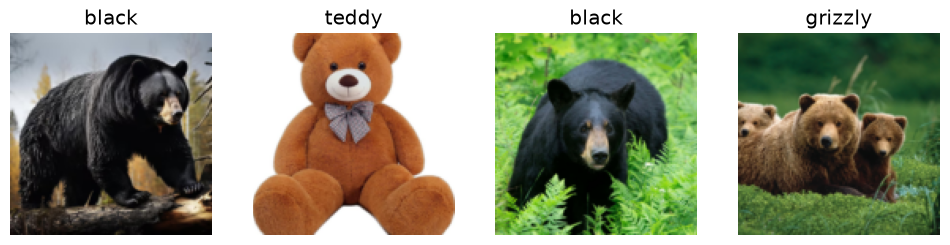

In [11]:
from fastai.data.all import *
from fastai.vision.all import *

bears = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    #imageblock is for images and categoryblock is for labels here labels are black, grizzly, and teddy
    #independent variables (x) is a image used for prediction and dependent variables (y) is label here which we need to categorized
    get_items=get_image_files,
    #how to get this files or data
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(128),
    #tensor underlying library in fast.ai needs all image to be of same size so resizing
)


dls = bears.dataloaders(path)

dls.valid.show_batch(max_n=4, nrows=1)
     

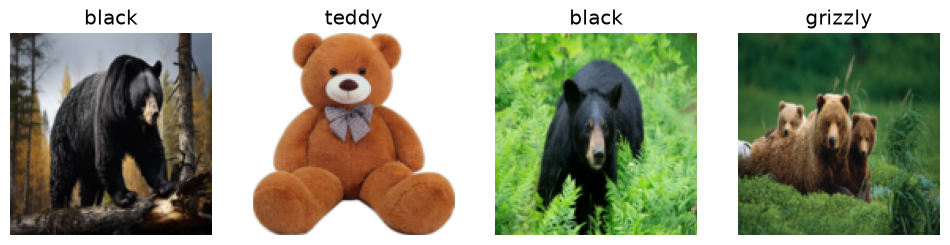

In [12]:
bears = bears.new(item_tfms=Resize(128, ResizeMethod.Squish))
dls = bears.dataloaders(path)
dls.valid.show_batch(max_n=4, nrows=1)

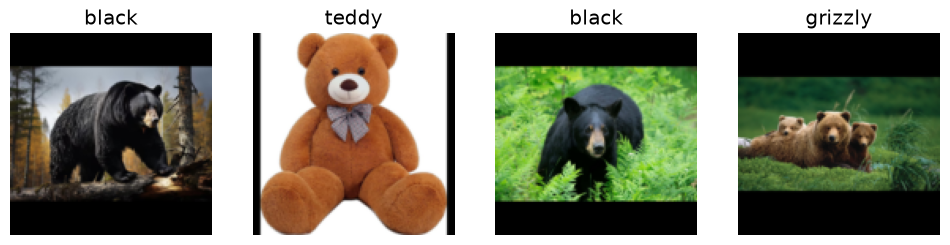

In [13]:

bears = bears.new(item_tfms=Resize(128, ResizeMethod.Pad, pad_mode='zeros'))
dls = bears.dataloaders(path)
dls.valid.show_batch(max_n=4, nrows=1)

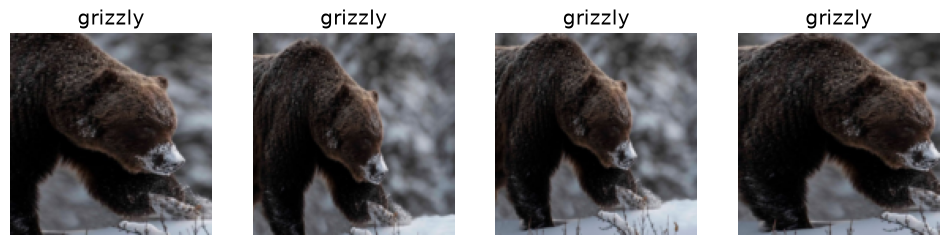

In [14]:

bears = bears.new(item_tfms=RandomResizedCrop(128, min_scale=0.3))
dls = bears.dataloaders(path)
dls.train.show_batch(max_n=4, nrows=1, unique=True)

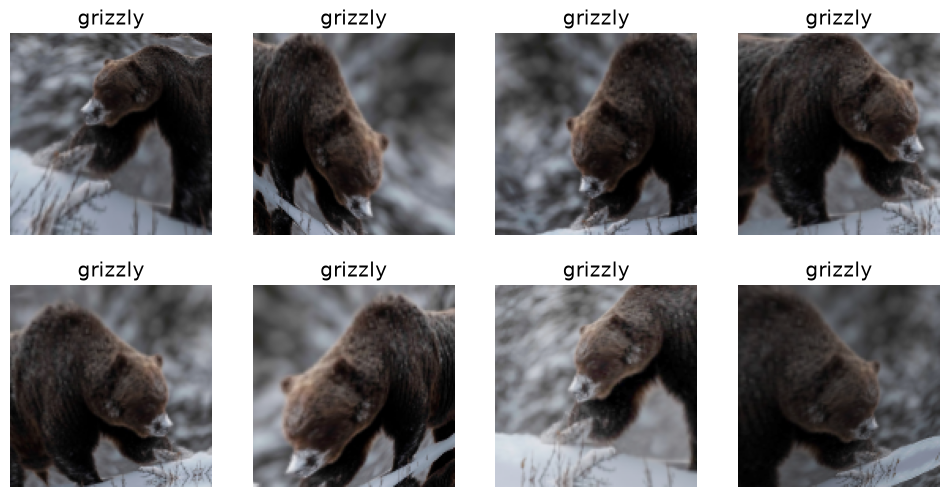

In [15]:
bears = bears.new(item_tfms=Resize(128), batch_tfms=aug_transforms(mult=2))
dls = bears.dataloaders(path)
dls.train.show_batch(max_n=8, nrows=2, unique=True)

In [34]:

bears = bears.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms())
dls = bears.dataloaders(path)

In [35]:

learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

epoch,train_loss,valid_loss,error_rate,time
0,1.894762,0.216193,0.098361,00:12


epoch,train_loss,valid_loss,error_rate,time
0,0.304762,0.087020,0.032787,00:13
1,0.209757,0.029576,0.016393,00:11
2,0.168326,0.021375,0.016393,00:12
3,0.133576,0.014996,0.000000,00:20


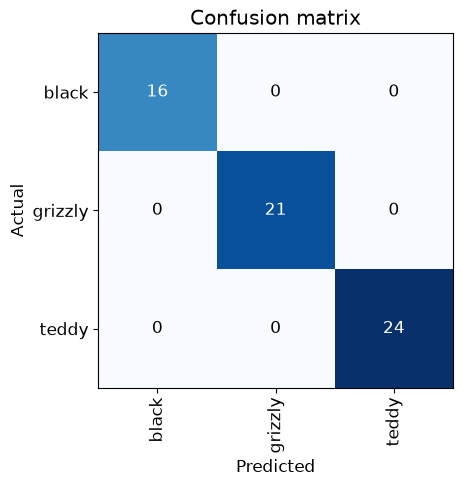

In [36]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

<div><progress max="1" value="0"></progress> 0.00% [0/1 00:00&lt;?]</div>

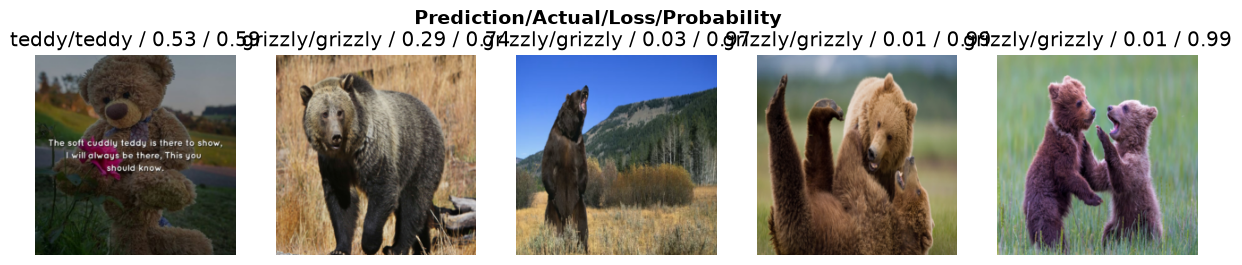

In [37]:

interp.plot_top_losses(5, nrows=1)

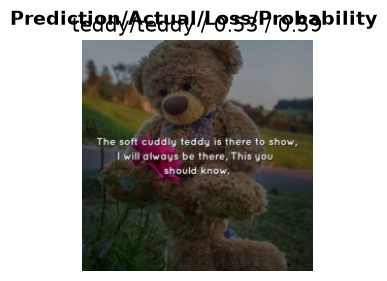

In [38]:
interp.plot_top_losses(1)

In [39]:
doc(interp.plot_top_losses)

Interpretation.plot_top_losses(k: int | collections.abc.MutableSequence, largest: bool = True, **kwargs)
Show `k` largest(/smallest) preds and losses. Implementation based on type dispatch

To get a prettier result with hyperlinks to source code and documentation, install nbdev: pip install nbdev


AttributeError: AxesImage.set() got an unexpected keyword argument 'ds_idx'

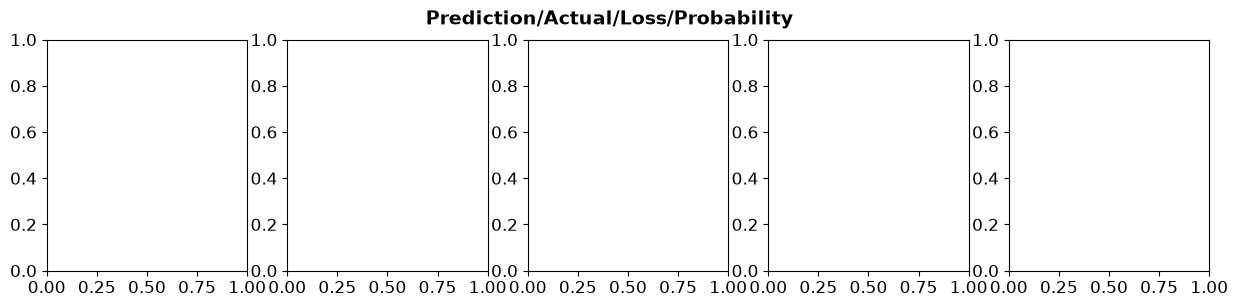

In [40]:
interp.plot_top_losses(5, nrows=1, ds_idx=0)

In [41]:
#hide_output
cleaner = ImageClassifierCleaner(learn)
cleaner

/Users/vikranthkaru/Desktop/abliteration/.venv/lib/python3.12/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [30]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()

In [42]:
learn.export()

In [43]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

In [44]:
learn_inf = load_learner(path/'export.pkl')

/Users/vikranthkaru/Desktop/abliteration/.venv/lib/python3.12/site-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [45]:
learn_inf.predict('0b921ade-6250-416f-b5fd-d113dc0a9ebc.jpg')

('grizzly', tensor(1), tensor([1.2865e-03, 9.9851e-01, 2.0447e-04]))

In [46]:
learn_inf.dls.vocab

['black', 'grizzly', 'teddy']

In [47]:
btn_upload = widgets.FileUpload()
btn_upload

FileUpload(value={}, description='Upload')

In [54]:

img = PILImage.create(btn_upload.data[-1])

In [55]:
print(img)

PILImage mode=RGB size=398x256


In [56]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

In [57]:

pred,pred_idx,probs = learn_inf.predict(img)

In [58]:
lbl_pred = widgets.Label()
lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'
lbl_pred

Label(value='Prediction: black; Probability: 0.9848')

In [59]:
btn_run = widgets.Button(description='Classify')
btn_run

Button(description='Classify', style=ButtonStyle())

In [60]:
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred,pred_idx,probs = learn_inf.predict(img)
    lbl_pred.value = f'Prediction: {pred}; Probability: {probs[pred_idx]:.04f}'

btn_run.on_click(on_click_classify)

In [61]:
btn_upload = widgets.FileUpload()

In [62]:
VBox([widgets.Label('Select your bear!'), 
      btn_upload, btn_run, out_pl, lbl_pred])